<a href="https://colab.research.google.com/github/yang200212/MSSP-6070/blob/main/Modules/Week_11/Participation_Activity_Week_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import userdata
import csv
import requests
import os
import subprocess
from pathlib import Path
from urllib.parse import urlparse

carto_key = 'cb1_57ys_1_23865597f50c387c73644e9b'
owner = 'yang200212'
repository = 'MSSP-6070'

clone_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

import subprocess
subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP-6070/MSSP-6070


In [5]:
!pip install geojson
!pip install geodatasets
!pip install mapclassify
!pip install cartoframes
%pip install -q geopandas folium mapclassify

  Using cached Jinja2-2.11.3-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached Jinja2-2.11.3-py2.py3-none-any.whl (125 kB)
  Attempting uninstall: jinja2
    Found existing installation: Jinja2 3.1.6
    Uninstalling Jinja2-3.1.6:
      Successfully uninstalled Jinja2-3.1.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
branca 0.8.2 requires jinja2>=3, but you have jinja2 2.11.3 which is incompatible.
flask 3.1.3 requires jinja2>=3.1.2, but you have jinja2 2.11.3 which is incompatible.
flask 3.1.3 requires markupsafe>=2.1.1, but you have markupsafe 2.0.1 which is incompatible.
sphinx 8.2.3 requires Jinja2>=3.1, but you have jinja2 2.11.3 which is incompatible.
nbconvert 7.17.2 requires jinja2>=3.0, but you have jinja2 2.11.3 which is incompatible.
jupyter-server 2.20.0 requires jinja2>=3.0.3, but you have jinja2 2.11.3 which is incompatible.
ERROR: pip's dep

In [6]:
import subprocess

subprocess.run(
    ['git', '-C', str(repo_path), 'pull', 'origin', 'main'],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/MSSP-6070', 'pull', 'origin', 'main'], returncode=0)

In [7]:
#Import libraries and find some data
import pandas as pd
import geojson as gpd
import geopandas as gp
import matplotlib.pyplot as plt
import mapclassify
import geopandas
import geodatasets
from geodatasets import get_path

In [17]:
ca_geo = gp.read_file("/content/MSSP-6070/MSSP-6070/Modules/Week_11/california-congressional-districts.geojson")
ca_pop = pd.read_csv("/content/MSSP-6070/MSSP-6070/Modules/Week_11/CA_Legislative_Districts.csv")

ca_geo.head()

,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.66700 39.30511, -121.6301..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


<Axes: >

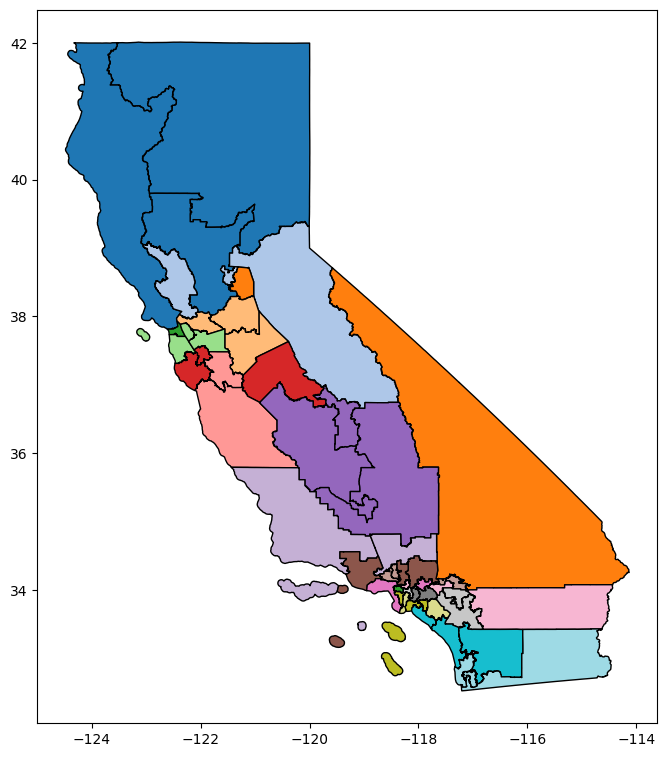

In [18]:
ca_geo.plot(figsize=(8,10), cmap='tab20', edgecolor='black', legend=True)

In [19]:
ca_geo["DISTRICT"] = ca_geo["Name"].astype(int)

ca_merged = ca_geo.merge(
    ca_pop[["DISTRICT", "POPULATION", "CVAP_19"]],
    on="DISTRICT",
    how="left"
)

ca_merged.tail()

,Name,description,descriptio,geometry,DISTRICT,POPULATION,CVAP_19
48,49,None,,"MULTIPOLYGON (((-117.44612 33.50502, -117.3642...",49,760066.0,543045.0
49,50,None,,"MULTIPOLYGON (((-117.19300 33.46202, -117.1924...",50,760067.0,530609.0
50,51,None,,"MULTIPOLYGON (((-116.90095 32.55316, -116.9280...",51,760065.0,543249.0
51,52,None,,"MULTIPOLYGON (((-117.29773 32.64201, -117.3092...",52,760066.0,468765.0
52,53,None,,"MULTIPOLYGON (((-117.18538 32.75873, -117.1788...",53,NaN,NaN


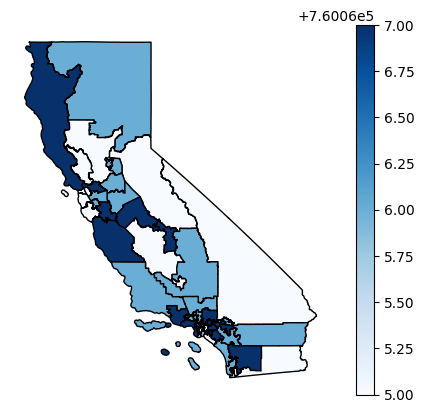

In [21]:
ca_merged.plot(
    column="POPULATION",
    cmap="Blues",
    legend=True,
    edgecolor="black"
)

plt.axis("off")
plt.show()

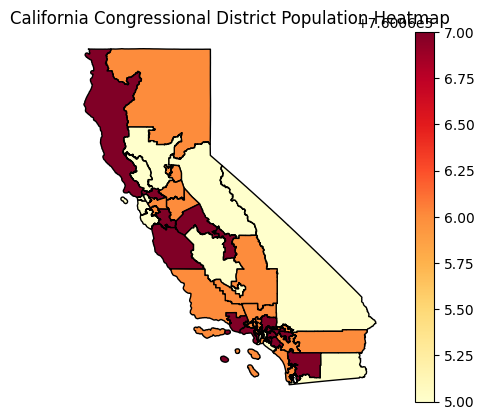

In [22]:
# Create a population heatmap
ca_merged.plot(
    column="POPULATION",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black"
)

plt.title("California Congressional District Population Heatmap")
plt.axis("off")
plt.show()

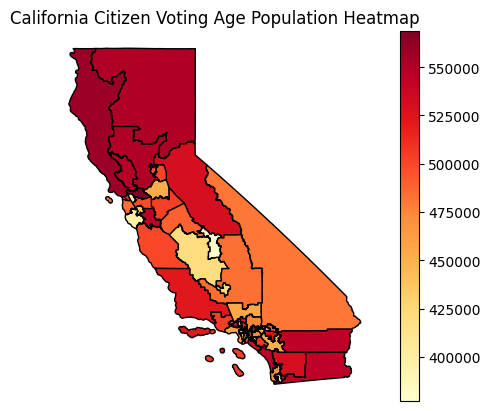

In [23]:
# Create a heatmap using Citizen Voting Age Population
ca_merged.plot(
    column="CVAP_19",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black"
)

plt.title("California Citizen Voting Age Population Heatmap")
plt.axis("off")
plt.show()

The geojson dataset contains 53 congressional districts, while the CSV contains population data for 52 districts. I matched the 52 available districts using district numbers and left District 53 blank due to missing population data.